CNN X-RAY CLASSIFICATION
Classes: NORMAL and PNEUMONIA

Dataset download and extraction completed.

IMAGE COUNT


,Training,Validation,Testing
NORMAL,1341,8,234
PNEUMONIA,3875,8,390



Total images: 5856
Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


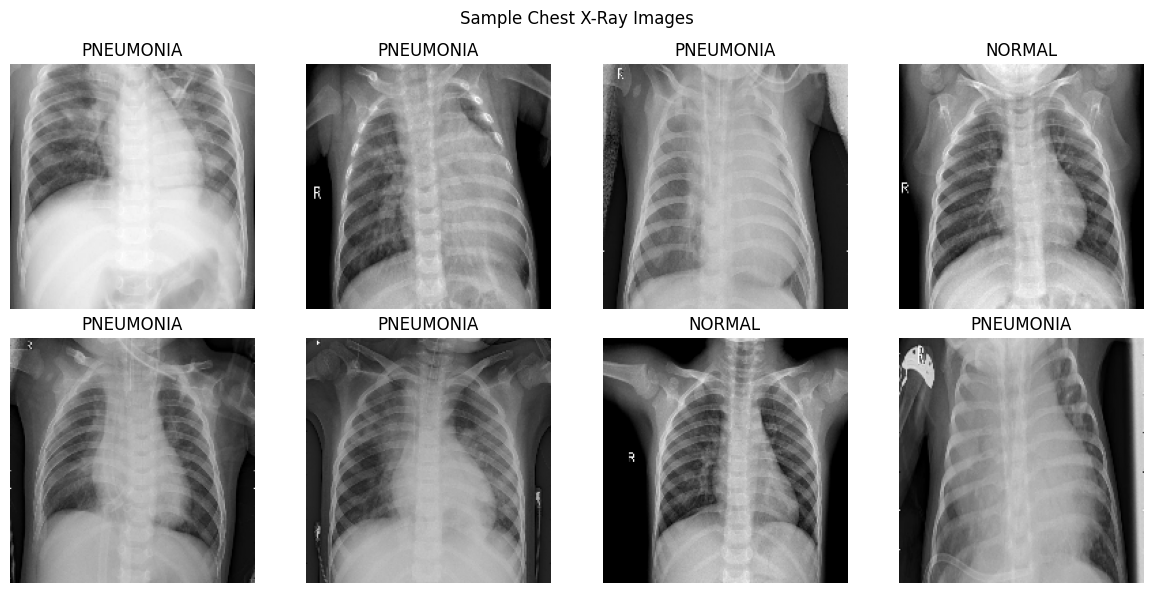


MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,646,529 (25.35 MB)

 Trainable params: 6,646,529 (25.35 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 398s 2s/step - accuracy: 0.9078 - loss: 0.2222 - val_accuracy: 0.8125 - val_loss: 0.4601
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 398s 2s/step - accuracy: 0.9617 - loss: 0.1023 - val_accuracy: 0.9375 - val_loss: 0.1386
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 425s 2s/step - accuracy: 0.9661 - loss: 0.0960 - val_accuracy: 1.0000 - val_loss: 0.1153
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 381s 2s/step - accuracy: 0.9753 - loss: 0.0679 - val_accuracy: 0.8125 - val_loss: 0.2872
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 377s 2s/step - accuracy: 0.9795 - loss: 0.0560 - val_accuracy: 1.0000 - val_loss: 0.0597


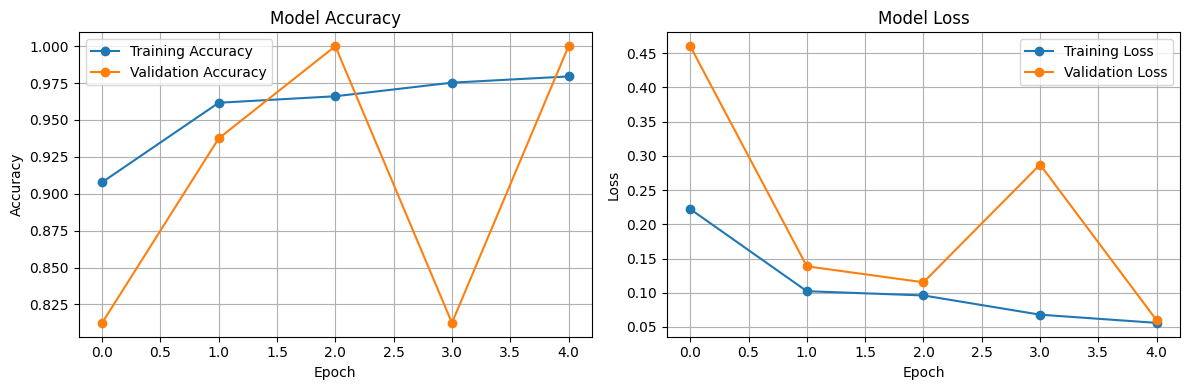

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 689ms/step - accuracy: 0.7853 - loss: 0.9768

TEST RESULTS
Test Loss     : 0.9768
Test Accuracy : 78.53%
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 666ms/step


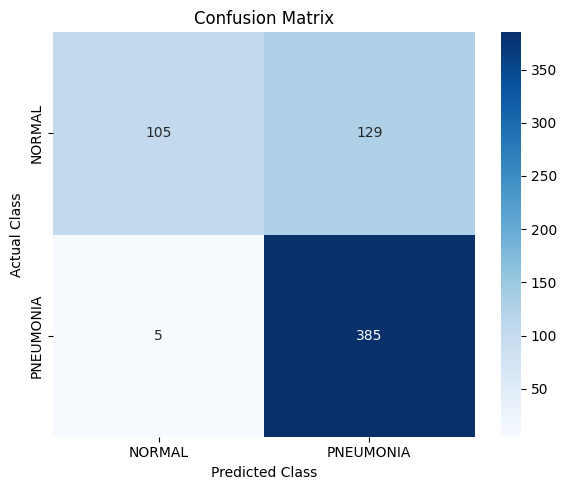


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9545    0.4487    0.6105       234
   PNEUMONIA     0.7490    0.9872    0.8518       390

    accuracy                         0.7853       624
   macro avg     0.8518    0.7179    0.7311       624
weighted avg     0.8261    0.7853    0.7613       624



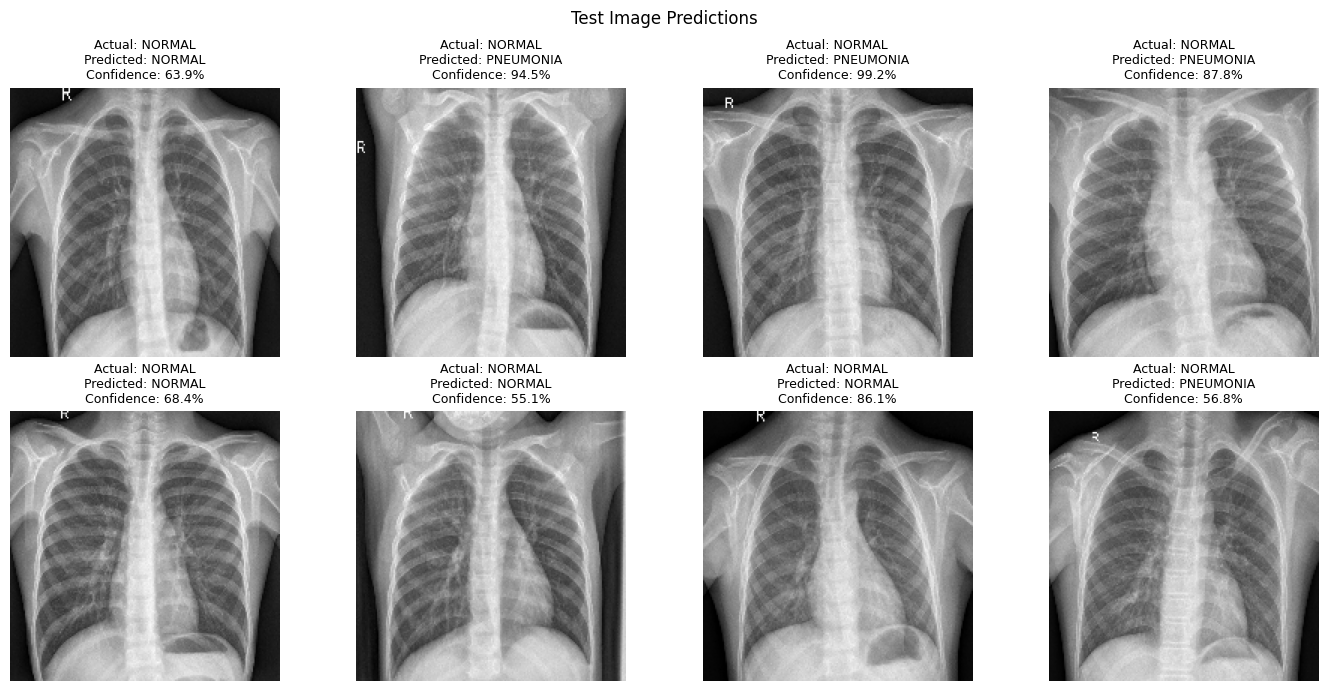


Saved model: /content/cnn_xray_classification.keras

EXPERIMENT COMPLETED


In [ ]:
# CNN X-RAY CLASSIFICATION: NORMAL vs PNEUMONIA


import os, zipfile, shutil, urllib.request, pathlib, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# 1. SETTINGS
tf.keras.utils.set_random_seed(42)
IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
EPOCHS = 5
DATA_URL = "https://codeload.github.com/probml/chest_xray_kaggle/zip/refs/heads/main"
ZIP_PATH = "/content/chest_xray_dataset.zip"
EXTRACT_PATH = "/content/chest_xray_dataset"

print("=" * 65)
print("CNN X-RAY CLASSIFICATION")
print("Classes: NORMAL and PNEUMONIA")
print("=" * 65)

# 2. DOWNLOAD AND EXTRACT DATASET
if not os.path.exists(os.path.join(EXTRACT_PATH, "chest_xray_kaggle-main")):
    print("\nDownloading chest X-ray dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    os.makedirs(EXTRACT_PATH, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_PATH)
    print("Dataset download and extraction completed.")

ROOT = os.path.join(EXTRACT_PATH, "chest_xray_kaggle-main")
TRAIN_DIR = os.path.join(ROOT, "train")
VAL_DIR = os.path.join(ROOT, "val")
TEST_DIR = os.path.join(ROOT, "test")

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Dataset folder not found: {folder}")

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

# 3. DATASET COUNTS
def count_images(folder):
    counts = {}
    for class_name in CLASS_NAMES:
        class_dir = os.path.join(folder, class_name)
        counts[class_name] = len([
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
    return counts

distribution = pd.DataFrame({
    "Training": count_images(TRAIN_DIR),
    "Validation": count_images(VAL_DIR),
    "Testing": count_images(TEST_DIR)
})
print("\nIMAGE COUNT")
display(distribution)
print("\nTotal images:", int(distribution.values.sum()))

# 4. LOAD IMAGES DIRECTLY FROM THE EXTRACTED FOLDERS
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels="inferred", label_mode="binary",
    class_names=CLASS_NAMES, color_mode="grayscale",
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=True,
    seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, labels="inferred", label_mode="binary",
    class_names=CLASS_NAMES, color_mode="grayscale",
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="binary",
    class_names=CLASS_NAMES, color_mode="grayscale",
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# 5. DISPLAY SAMPLE X-RAY IMAGES
images, labels = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.squeeze(images[i]), cmap="gray")
    plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
    plt.axis("off")
plt.suptitle("Sample Chest X-Ray Images")
plt.tight_layout()
plt.show()

# 6. BUILD CNN MODEL
model = models.Sequential([
    layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 1)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nMODEL SUMMARY")
model.summary()

# 7. TRAIN THE MODEL
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1
)

# 8. TRAINING AND VALIDATION GRAPHS
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. TEST SET EVALUATION
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print("\nTEST RESULTS")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# 10. PREDICTIONS, CONFUSION MATRIX AND CLASSIFICATION REPORT
y_true = np.concatenate([y.numpy().ravel() for _, y in test_ds]).astype(int)
y_prob = model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=CLASS_NAMES, zero_division=0, digits=4
))

# 11. DISPLAY SAMPLE TEST PREDICTIONS
test_images, test_labels = next(iter(test_ds))
sample_prob = model.predict(test_images[:8], verbose=0).ravel()
plt.figure(figsize=(14, 7))
for i in range(min(8, len(test_images))):
    actual = CLASS_NAMES[int(test_labels[i].numpy()[0])]
    predicted = CLASS_NAMES[int(sample_prob[i] >= 0.5)]
    confidence = sample_prob[i] if predicted == "PNEUMONIA" else 1 - sample_prob[i]
    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.squeeze(test_images[i]), cmap="gray")
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\nConfidence: {confidence*100:.1f}%",
        fontsize=9
    )
    plt.axis("off")
plt.suptitle("Test Image Predictions")
plt.tight_layout()
plt.show()

# 12. SAVE TRAINED MODEL
MODEL_PATH = "/content/cnn_xray_classification.keras"
model.save(MODEL_PATH)
print(f"\nSaved model: {MODEL_PATH}")

